# Benchmarking Network Inference Methods on Transient Data

This notebook compares multiple methods on transient biological time-series data.


In [1]:
import numpy as np
import graph_tool.all as gt
import sys
import os
import subprocess
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error, roc_curve, precision_recall_curve, auc
from scipy.stats import spearmanr
import statsmodels.api as sm
import pysindy as ps



# Add the parent directory to sys.path so we can import our modules and gene_expr

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), os.pardir)))

from inference_pipeline.data_generation.network_generator import generate_scale_free_W
from inference_pipeline.data_generation.simulator import simulate_realistic_pairs
from inference_pipeline.inference.mcmc_engine import run_burn_in, run_posterior_sampling, compute_ensemble_stats
from inference_pipeline.inference.metrics import plot_probabilistic_network, plot_inferred_vs_true_am, compute_reconstruction_metrics
from inference_pipeline.prediction.export_utils import export_ensemble_to_bin, export_true_to_bin
from gene_expr import GeneExprBlockState


In [68]:
N = 10
m = 1
seed_network = 42

dt_sim = 0.005
dt_sample = 1.0
dt_meas = dt_sample
M_train = 50
M_test = 50
t_window = (0.0, 4.0)

mean_d = 0.5
mean_V = 2.0
D_base = 0.02

## Data Generation

In [69]:
# Generate TRUE network
W_true = generate_scale_free_W(N, m, seed=seed_network)
W_true_binary = (W_true != 0).astype(int)
theta_true = [np.log(mean_d), np.log(mean_V), np.log(D_base)]

# 2. Simulate Training and Test Data (Transient Region)
print("Simulating transient training data...")
s_train, _, _, _, _ = simulate_realistic_pairs(
    W_true, M=M_train, dt_sim=dt_sim, dt_sample=dt_sample, dt_meas=dt_meas, 
    D_base=D_base, mean_d=mean_d, std_d=0.0, mean_V=mean_V, std_V=0.0, seed=100, t_window=t_window
)

print("Simulating transient test data...")
s_test, _, _, _, _ = simulate_realistic_pairs(
    W_true, M=M_test, dt_sim=dt_sim, dt_sample=dt_sample, dt_meas=dt_meas, 
    D_base=D_base, mean_d=mean_d, std_d=0.0, mean_V=mean_V, std_V=0.0, seed=200, t_window=t_window
)

# Prepare data arrays for ML models
X_train_in = np.array([pair[:, 0] for pair in s_train])
X_train_out = np.array([pair[:, 1] for pair in s_train])
dX_train = (X_train_out - X_train_in) / dt_meas

X_test_in = np.array([pair[:, 0] for pair in s_test])
X_test_out = np.array([pair[:, 1] for pair in s_test])
dX_test = (X_test_out - X_test_in) / dt_meas

results = {}

def calc_all_metrics(y_true_binary, y_true_continuous, y_scores, y_inferred_continuous=None):
    mask = ~np.eye(N, dtype=bool)
    y_true_b = y_true_binary[mask]
    y_s = y_scores[mask]
    
    fpr, tpr, _ = roc_curve(y_true_b, y_s)
    roc_auc = auc(fpr, tpr)
    
    precision, recall, _ = precision_recall_curve(y_true_b, y_s)
    pr_auc = auc(recall, precision)
    
    spearman_corr, _ = spearmanr(np.abs(y_true_continuous[mask]), np.abs(y_s))
    
    sign_acc = np.nan
    if y_inferred_continuous is not None:
        true_edges_mask = (y_true_b == 1)
        if np.any(true_edges_mask):
            true_signs = np.sign(y_true_continuous[mask][true_edges_mask])
            inf_signs = np.sign(y_inferred_continuous[mask][true_edges_mask])
            sign_acc = np.mean(true_signs == inf_signs)
    
    return fpr, tpr, roc_auc, precision, recall, pr_auc, spearman_corr, sign_acc


Simulating transient training data...
Simulating transient test data...


## 1. Random Forest (dynGENIE3 equivalent)


In [70]:
print("Running Random Forest (dynGENIE3 equivalent)...")
rf_edge_scores = np.zeros((N, N))
rf_train_preds = np.zeros_like(X_train_out)
rf_test_preds = np.zeros_like(X_test_out)

for i in range(N):
    mask = np.ones(N, dtype=bool)
    mask[i] = False
    rf = RandomForestRegressor(n_estimators=200, random_state=12)
    rf.fit(X_train_in[:, mask], X_train_out[:, i])
    rf_edge_scores[i, mask] = rf.feature_importances_
    rf_train_preds[:, i] = rf.predict(X_train_in[:, mask])
    rf_test_preds[:, i] = rf.predict(X_test_in[:, mask])
    
fpr, tpr, roc_auc, precision, recall, pr_auc, spearman, sign_acc = calc_all_metrics(
    W_true_binary, W_true, rf_edge_scores, y_inferred_continuous=None
)
rf_train_mse = mean_squared_error(X_train_out, rf_train_preds)
rf_test_mse = mean_squared_error(X_test_out, rf_test_preds)


results['dynGENIE3 (RF)'] = {
    'AUPRC': pr_auc, 'AUROC': roc_auc,
    'Train_MSE': rf_train_mse, 'Test_MSE': rf_test_mse,
    'Spearman': spearman, 'Sign Accuracy': sign_acc,
    'FPR': fpr, 'TPR': tpr, 'Precision': precision, 'Recall': recall,
    'W': rf_edge_scores
}


Running Random Forest (dynGENIE3 equivalent)...


--- Random Forest Results ---
AUPRC:     0.2590
AUROC:     0.7106
Spearman:  0.2174
Train MSE: 0.0053
Test MSE:  0.0465


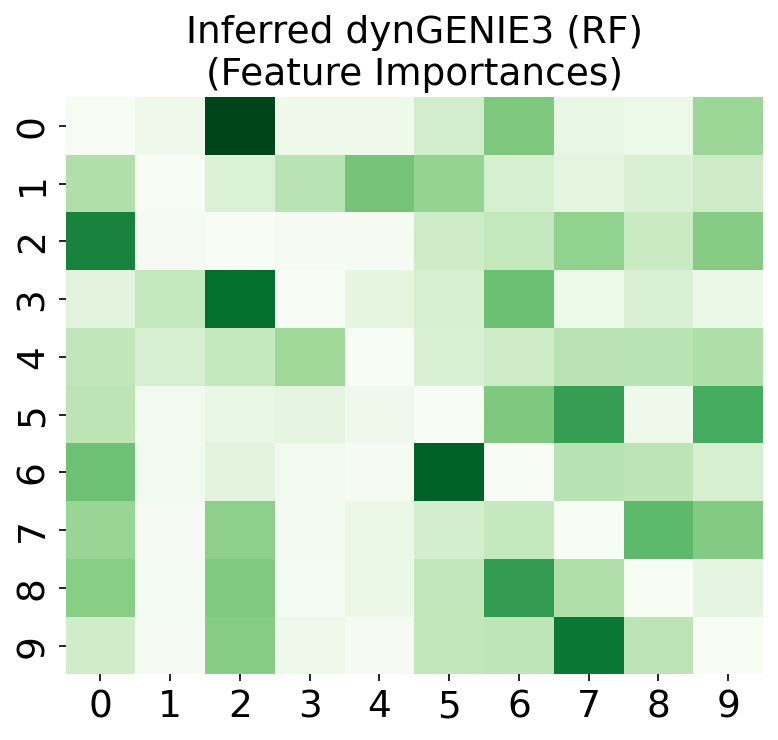

In [71]:
print("--- Random Forest Results ---")
print(f"AUPRC:     {pr_auc:.4f}")
print(f"AUROC:     {roc_auc:.4f}")
print(f"Spearman:  {spearman:.4f}")
print(f"Train MSE: {rf_train_mse:.4f}")
print(f"Test MSE:  {rf_test_mse:.4f}")

plt.figure(figsize=(6, 5))
W_rf_plot = rf_edge_scores.copy()
np.fill_diagonal(W_rf_plot, 0)
sns.heatmap(W_rf_plot, cmap='Greens', cbar=False)
plt.title('Inferred dynGENIE3 (RF)\n(Feature Importances)')
plt.show()


## 2. Sparse ODE (Lasso)


In [72]:
print("Running Sparse ODE (Lasso)...")
lasso_edge_scores = np.zeros((N, N))
lasso_coefs_signed = np.zeros((N, N))
lasso_train_preds = np.zeros_like(dX_train)
lasso_test_preds = np.zeros_like(dX_test)

for i in range(N):
    mask = np.ones(N, dtype=bool)
    mask[i] = False
    lasso = Lasso(alpha=0.01, random_state=42)
    lasso.fit(X_train_in[:, mask], dX_train[:, i])
    lasso_edge_scores[i, mask] = np.abs(lasso.coef_)
    lasso_coefs_signed[i, mask] = lasso.coef_
    lasso_train_preds[:, i] = lasso.predict(X_train_in[:, mask])
    lasso_test_preds[:, i] = lasso.predict(X_test_in[:, mask])
    
fpr, tpr, roc_auc, precision, recall, pr_auc, spearman, sign_acc = calc_all_metrics(
    W_true_binary, W_true, lasso_edge_scores, y_inferred_continuous=lasso_coefs_signed
)

lasso_X_train_preds = X_train_in + lasso_train_preds * dt_meas
lasso_X_test_preds = X_test_in + lasso_test_preds * dt_meas

lasso_train_mse = mean_squared_error(X_train_out, lasso_X_train_preds)
lasso_test_mse = mean_squared_error(X_test_out, lasso_X_test_preds)

results['Sparse ODE (Lasso)'] = {
    'AUPRC': pr_auc, 'AUROC': roc_auc,
    'Train_MSE': lasso_train_mse, 'Test_MSE': lasso_test_mse,
    'Spearman': spearman, 'Sign Accuracy': sign_acc,
    'FPR': fpr, 'TPR': tpr, 'Precision': precision, 'Recall': recall,
    'W': lasso_edge_scores
}


Running Sparse ODE (Lasso)...


--- Lasso Results ---
AUPRC:     0.0803
AUROC:     0.4486
Spearman:  -0.0594
Sign Acc:  0.2222
Train MSE: 0.0281
Test MSE:  0.0319


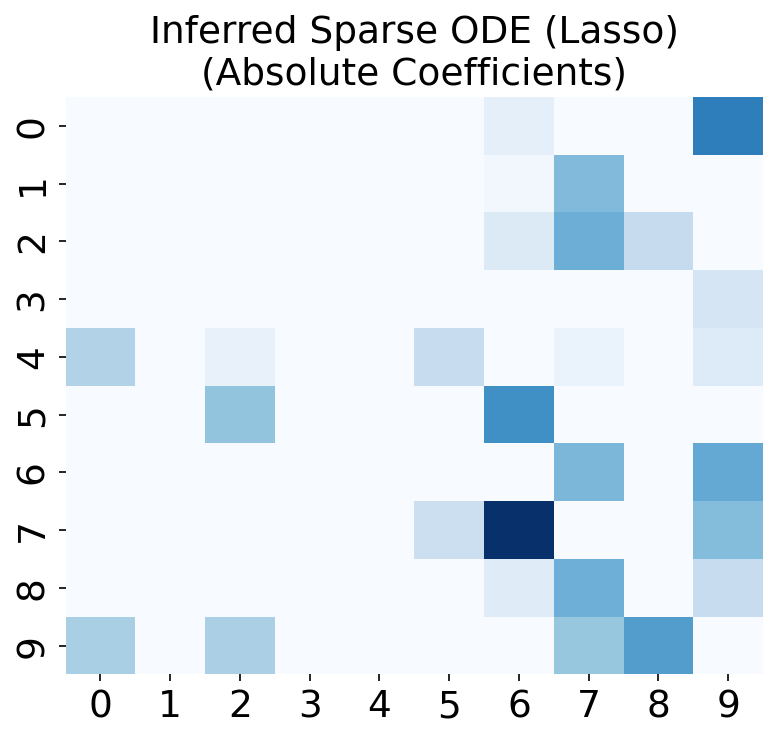

In [73]:
print("--- Lasso Results ---")
print(f"AUPRC:     {pr_auc:.4f}")
print(f"AUROC:     {roc_auc:.4f}")
print(f"Spearman:  {spearman:.4f}")
print(f"Sign Acc:  {sign_acc:.4f}")
print(f"Train MSE: {lasso_train_mse:.4f}")
print(f"Test MSE:  {lasso_test_mse:.4f}")

plt.figure(figsize=(6, 5))
W_lasso_plot = lasso_edge_scores.copy()
np.fill_diagonal(W_lasso_plot, 0)
sns.heatmap(W_lasso_plot, cmap='Blues', cbar=False)
plt.title('Inferred Sparse ODE (Lasso)\n(Absolute Coefficients)')
plt.show()


## 3. Granger Causality (VAR-like F-test)


In [74]:
print("Running Granger Causality...")
gc_edge_scores = np.zeros((N, N))

for i in range(N):
    y = X_train_out[:, i]
    X_null = sm.add_constant(X_train_in[:, i])
    model_null = sm.OLS(y, X_null).fit()
    rss_null = np.sum(model_null.resid**2)
    
    for j in range(N):
        if i == j: continue
        X_alt = sm.add_constant(X_train_in[:, [i, j]])
        model_alt = sm.OLS(y, X_alt).fit()
        rss_alt = np.sum(model_alt.resid**2)
        
        # F-statistic for the nested model
        F = ((rss_null - rss_alt) / 1) / (rss_alt / (M_train - 3))
        gc_edge_scores[i, j] = F

fpr, tpr, roc_auc, precision, recall, pr_auc, spearman, sign_acc = calc_all_metrics(
    W_true_binary, W_true, gc_edge_scores, y_inferred_continuous=None
)

results['Granger Causality'] = {
    'AUPRC': pr_auc, 'AUROC': roc_auc,
    'Train_MSE': np.nan, 'Test_MSE': np.nan, # F-test doesn't strictly provide a unified forward model for prediction
    'Spearman': spearman, 'Sign Accuracy': sign_acc,
    'FPR': fpr, 'TPR': tpr, 'Precision': precision, 'Recall': recall,
    'W': gc_edge_scores
}


Running Granger Causality...


--- Granger Causality Results ---
AUPRC:     0.2809
AUROC:     0.7394
Spearman:  0.2561
Sign Acc:  N/A
Train MSE: N/A
Test MSE:  N/A


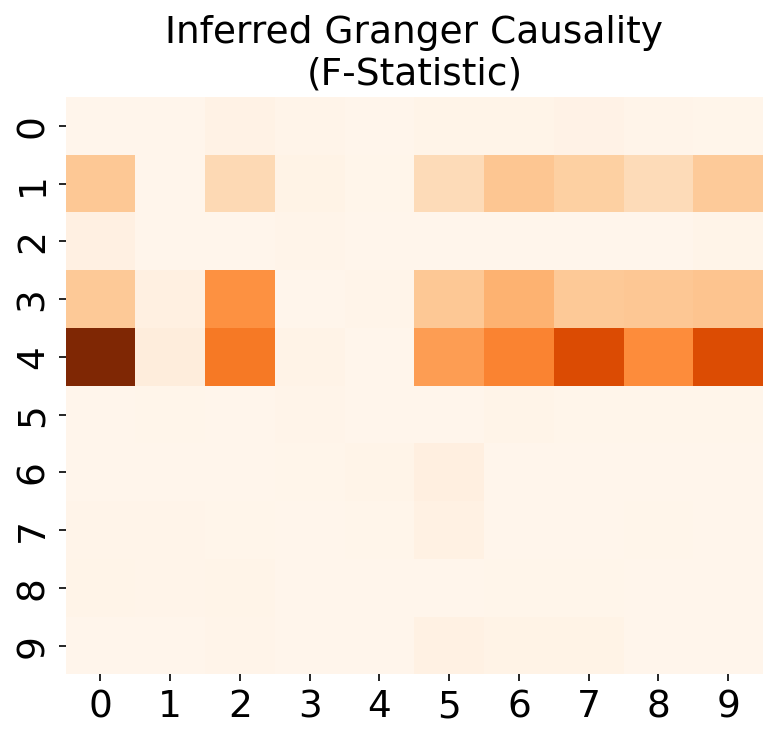

In [75]:
print("--- Granger Causality Results ---")
print(f"AUPRC:     {pr_auc:.4f}")
print(f"AUROC:     {roc_auc:.4f}")
print(f"Spearman:  {spearman:.4f}")
print(f"Sign Acc:  N/A")
print(f"Train MSE: N/A")
print(f"Test MSE:  N/A")

plt.figure(figsize=(6, 5))
W_gc_plot = gc_edge_scores.copy()
np.fill_diagonal(W_gc_plot, 0)
sns.heatmap(W_gc_plot, cmap='Oranges', cbar=False)
plt.title('Inferred Granger Causality\n(F-Statistic)')
plt.show()


## 4. PySINDy (STLSQ)


In [76]:
print("Running PySINDy...")
model = ps.SINDy(optimizer=ps.STLSQ(threshold=0.01, alpha=0.01),
                 feature_library=ps.PolynomialLibrary(degree=1, include_interaction=False, include_bias=False))
model.fit(X_train_in, t=dt_meas, x_dot=dX_train)

sindy_coefs = model.coefficients()  # shape (N, N)
# Zero out diagonals since we are banning self-loops
sindy_coefs_signed = sindy_coefs.copy()
np.fill_diagonal(sindy_coefs_signed, 0)
sindy_edge_scores = np.abs(sindy_coefs_signed)

fpr, tpr, roc_auc, precision, recall, pr_auc, spearman, sign_acc = calc_all_metrics(
    W_true_binary, W_true, sindy_edge_scores, y_inferred_continuous=sindy_coefs_signed
)

# SINDy integrates the system, but we can just use the derivative to predict X_out over dt
sindy_train_preds = X_train_in + model.predict(X_train_in) * dt_meas
sindy_test_preds = X_test_in + model.predict(X_test_in) * dt_meas

sindy_train_mse = mean_squared_error(X_train_out, sindy_train_preds)
sindy_test_mse = mean_squared_error(X_test_out, sindy_test_preds)

results['PySINDy'] = {
    'AUPRC': pr_auc, 'AUROC': roc_auc,
    'Train_MSE': sindy_train_mse, 'Test_MSE': sindy_test_mse,
    'Spearman': spearman, 'Sign Accuracy': sign_acc,
    'FPR': fpr, 'TPR': tpr, 'Precision': precision, 'Recall': recall,
    'W': sindy_edge_scores
}


Running PySINDy...


--- PySINDy Results ---
AUPRC:     0.1696
AUROC:     0.7229
Spearman:  0.2345
Sign Acc:  1.0000
Train MSE: 0.0351
Test MSE:  0.0707


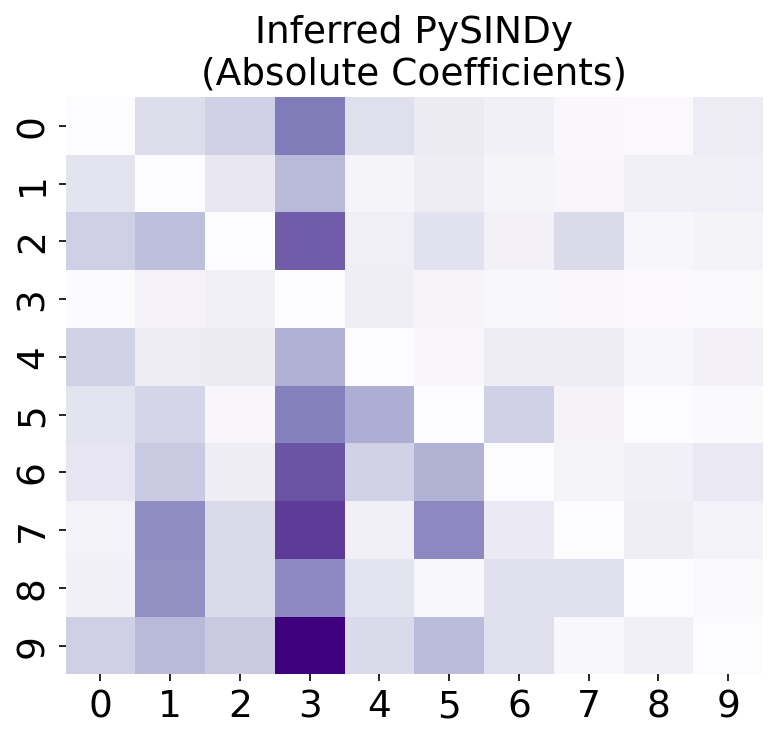

In [77]:
print("--- PySINDy Results ---")
print(f"AUPRC:     {pr_auc:.4f}")
print(f"AUROC:     {roc_auc:.4f}")
print(f"Spearman:  {spearman:.4f}")
print(f"Sign Acc:  {sign_acc:.4f}")
print(f"Train MSE: {sindy_train_mse:.4f}")
print(f"Test MSE:  {sindy_test_mse:.4f}")

plt.figure(figsize=(6, 5))
W_sindy_plot = sindy_edge_scores.copy()
np.fill_diagonal(W_sindy_plot, 0)
sns.heatmap(W_sindy_plot, cmap='Purples', cbar=False)
plt.title('Inferred PySINDy\n(Absolute Coefficients)')
plt.show()


## 5. Graph-Tool SDE


In [78]:
print("Running Graph-Tool SDE...")
from inference_pipeline.inference.mcmc_engine import run_burn_in, run_posterior_sampling, compute_ensemble_stats

# Instantiate an empty graph in graph-tool format
g_init = gt.Graph(directed=True)
g_init.add_vertex(N)

# Add ~5% density of random edges to jump-start the MCMC
num_initial_edges = max(1, int(N * N * 0.05))
possible_edges = [(u, v) for u in range(N) for v in range(N) if u != v]
np.random.shuffle(possible_edges)
for u, v in possible_edges[:num_initial_edges]:
    g_init.add_edge(u, v)

# Initialize the custom state with an uninformative prior
initial_theta = [0.0, 0.0, np.log(0.05)]
state = GeneExprBlockState(s_train, dt=dt_meas, g=g_init, state_args=dict(deg_corr=False), theta=initial_theta,
                           use_em_likelihood=False)
print(f"Initial description length: {state.entropy():.4f}")

# Phase 1: Burn-in
state = run_burn_in(state, n_burnin=100, theta_mode="global")

# Phase 2: Posterior Sampling
n_samples = 100
W_ensemble, theta_ensemble = run_posterior_sampling(state, N, n_samples=n_samples, delta_k=1, theta_mode="global")

# Compute and save ensemble stats
edge_probabilities, weight_mean, weight_std = compute_ensemble_stats(W_ensemble)
gt_edge_scores = edge_probabilities * np.abs(weight_mean)



fpr, tpr, roc_auc, precision, recall, pr_auc, spearman, sign_acc = calc_all_metrics(
    W_true_binary, W_true, gt_edge_scores, y_inferred_continuous=weight_mean
)

# --- Compute GT MSE ---
def sigmoid_np(x):
    x = np.clip(x, -50, 50)
    return 1.0 / (1.0 + np.exp(-x))
    
theta_mean = np.mean(theta_ensemble, axis=0)
d_mean = np.exp(theta_mean[0])
V_mean = np.exp(theta_mean[1])

def predict_sde(X_in, W, d, V, dt_meas, dt_sim):
    n_steps = int(np.round(dt_meas / dt_sim))
    X_pred = X_in.copy()
    for _ in range(n_steps):
        drift = -d * X_pred + V * sigmoid_np(np.dot(X_pred, W.T))
        X_pred = np.maximum(X_pred + dt_sim * drift, 0.01)
    return X_pred

gt_train_preds = predict_sde(X_train_in, weight_mean, d_mean, V_mean, dt_meas, dt_sim)
gt_test_preds = predict_sde(X_test_in, weight_mean, d_mean, V_mean, dt_meas, dt_sim)

gt_train_mse = mean_squared_error(X_train_out, gt_train_preds)
gt_test_mse = mean_squared_error(X_test_out, gt_test_preds)

results['Graph-Tool SDE'] = {
    'AUPRC': pr_auc, 'AUROC': roc_auc,
    'Train MSE': gt_train_mse, 'Test MSE': gt_test_mse,
    'Spearman': spearman, 'Sign Accuracy': sign_acc,
    'FPR': fpr, 'TPR': tpr, 'Precision': precision, 'Recall': recall,
    'W': gt_edge_scores
}


np.savez_compressed(
    "data/Graph-Tool_SDE_results.npz", 
    W_ensemble=W_ensemble, 
    theta_ensemble=theta_ensemble,
    edge_probabilities=edge_probabilities,
    weight_mean=weight_mean,
    weight_std=weight_std,
    AUROC=roc_auc, AUPRC=pr_auc, Train_MSE=gt_train_mse, Test_MSE=gt_test_mse,
    Spearman=spearman, Sign_Accuracy=sign_acc,
    FPR=fpr, TPR=tpr, Precision=precision, Recall=recall,
    W=gt_edge_scores
)

Running Graph-Tool SDE...
Initial description length: 6158.9006

--- PHASE 1: Equilibration (100 sweeps) ---
Burn-in Sweep  1/100: Entropy = 1395.2040 (dS_topo = -2660.5912, dS_param = -2103.1055, moves = 6145)
Burn-in Sweep 10/100: Entropy = 741.0361 (dS_topo = -10.6457, dS_param =  -4.0498, moves = 6009)
Burn-in Sweep 20/100: Entropy = 751.2037 (dS_topo =  -9.8953, dS_param =  -0.3329, moves = 6863)
Burn-in Sweep 30/100: Entropy = 776.4648 (dS_topo = -41.3838, dS_param =  -0.2335, moves = 5126)
Burn-in Sweep 40/100: Entropy = 737.4547 (dS_topo =  41.3404, dS_param =  -0.8865, moves = 8255)
Burn-in Sweep 50/100: Entropy = 883.0621 (dS_topo =  15.2034, dS_param =  -0.1245, moves = 5007)
Burn-in Sweep 60/100: Entropy = 967.6333 (dS_topo =  53.5907, dS_param =  -0.0434, moves = 7528)
Burn-in Sweep 70/100: Entropy = 964.5253 (dS_topo =   6.6606, dS_param =  -0.2155, moves = 5568)
Burn-in Sweep 80/100: Entropy = 927.1337 (dS_topo =  37.9772, dS_param =  -0.2404, moves = 6592)
Burn-in Sweep

--- Graph-Tool SDE Results ---
AUPRC:     0.8783
AUROC:     0.9465
Spearman:  0.4711
Sign Acc:  1.0000
Train MSE: 0.0736
Test MSE:  0.0805


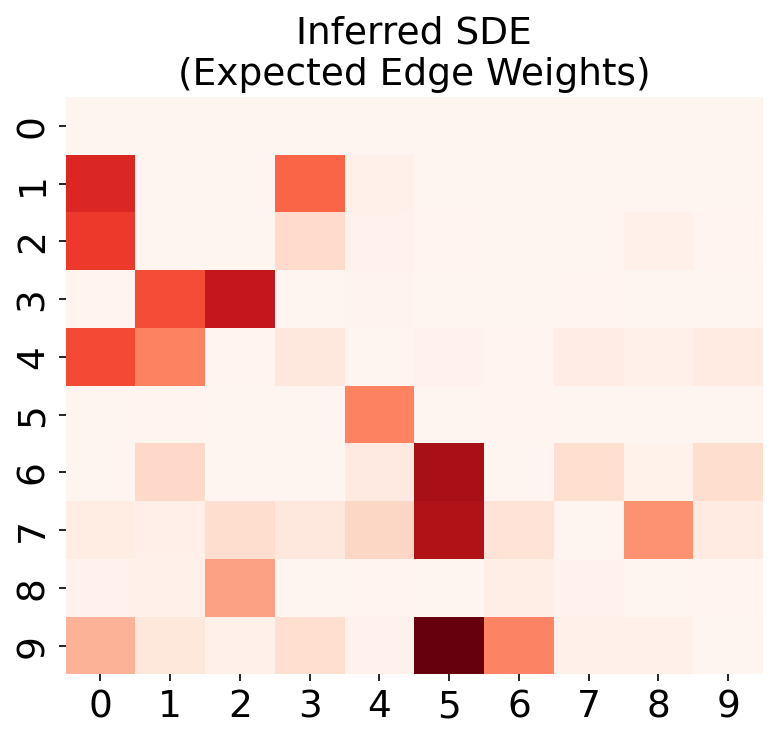

In [80]:
print("--- Graph-Tool SDE Results ---")
print(f"AUPRC:     {results['Graph-Tool SDE']['AUPRC']:.4f}")
print(f"AUROC:     {results['Graph-Tool SDE']['AUROC']:.4f}")
print(f"Spearman:  {results['Graph-Tool SDE']['Spearman']:.4f}")
print(f"Sign Acc:  {results['Graph-Tool SDE']['Sign Accuracy']:.4f}")
print(f"Train MSE: {results['Graph-Tool SDE']['Train MSE']:.4f}")
print(f"Test MSE:  {results['Graph-Tool SDE']['Test MSE']:.4f}")

plt.figure(figsize=(6, 5))
W_gt_plot = gt_edge_scores.copy()
np.fill_diagonal(W_gt_plot, 0)
sns.heatmap(W_gt_plot, cmap='Reds', cbar=False)
plt.title('Inferred SDE\n(Expected Edge Weights)')
plt.show()


## 6. Graph-Tool SDE (EM)

In [81]:
print("Running Graph-Tool SDE...")
from inference_pipeline.inference.mcmc_engine import run_burn_in, run_posterior_sampling, compute_ensemble_stats

# Instantiate an empty graph in graph-tool format
g_init = gt.Graph(directed=True)
g_init.add_vertex(N)

# Add ~5% density of random edges to jump-start the MCMC
num_initial_edges = max(1, int(N * N * 0.05))
possible_edges = [(u, v) for u in range(N) for v in range(N) if u != v]
np.random.shuffle(possible_edges)
for u, v in possible_edges[:num_initial_edges]:
    g_init.add_edge(u, v)

# Initialize the custom state with an uninformative prior
initial_theta = [0.0, 0.0, np.log(0.05)]
state = GeneExprBlockState(s_train, dt=dt_meas, g=g_init, state_args=dict(deg_corr=False), theta=initial_theta,
                           use_em_likelihood=True)
print(f"Initial description length: {state.entropy():.4f}")

# Phase 1: Burn-in
state = run_burn_in(state, n_burnin=100, theta_mode="global")

# Phase 2: Posterior Sampling
n_samples = 100
W_ensemble, theta_ensemble = run_posterior_sampling(state, N, n_samples=n_samples, delta_k=1, theta_mode="global")

# Compute and save ensemble stats
edge_probabilities, weight_mean, weight_std = compute_ensemble_stats(W_ensemble)
gt_edge_scores = edge_probabilities * np.abs(weight_mean)



fpr, tpr, roc_auc, precision, recall, pr_auc, spearman, sign_acc = calc_all_metrics(
    W_true_binary, W_true, gt_edge_scores, y_inferred_continuous=weight_mean
)

# --- Compute GT MSE ---
def sigmoid_np(x):
    x = np.clip(x, -50, 50)
    return 1.0 / (1.0 + np.exp(-x))
    
theta_mean = np.mean(theta_ensemble, axis=0)
d_mean = np.exp(theta_mean[0])
V_mean = np.exp(theta_mean[1])

def predict_sde(X_in, W, d, V, dt_meas, dt_sim):
    n_steps = int(np.round(dt_meas / dt_sim))
    X_pred = X_in.copy()
    for _ in range(n_steps):
        drift = -d * X_pred + V * sigmoid_np(np.dot(X_pred, W.T))
        X_pred = np.maximum(X_pred + dt_sim * drift, 0.01)
    return X_pred

gt_train_preds = predict_sde(X_train_in, weight_mean, d_mean, V_mean, dt_meas, dt_sim)
gt_test_preds = predict_sde(X_test_in, weight_mean, d_mean, V_mean, dt_meas, dt_sim)

gt_train_mse = mean_squared_error(X_train_out, gt_train_preds)
gt_test_mse = mean_squared_error(X_test_out, gt_test_preds)

results['Graph-Tool SDE (EM)'] = {
    'AUPRC': pr_auc, 'AUROC': roc_auc,
    'Train MSE': gt_train_mse, 'Test MSE': gt_test_mse,
    'Spearman': spearman, 'Sign Accuracy': sign_acc,
    'FPR': fpr, 'TPR': tpr, 'Precision': precision, 'Recall': recall,
    'W': gt_edge_scores
}


np.savez_compressed(
    "data/Graph-Tool_SDE_EM_results.npz", 
    W_ensemble=W_ensemble, 
    theta_ensemble=theta_ensemble,
    edge_probabilities=edge_probabilities,
    weight_mean=weight_mean,
    weight_std=weight_std,
    AUROC=roc_auc, AUPRC=pr_auc, Train_MSE=gt_train_mse, Test_MSE=gt_test_mse,
    Spearman=spearman, Sign_Accuracy=sign_acc,
    FPR=fpr, TPR=tpr, Precision=precision, Recall=recall,
    W=gt_edge_scores
)

Running Graph-Tool SDE...
Initial description length: 3957.6294

--- PHASE 1: Equilibration (100 sweeps) ---
Burn-in Sweep  1/100: Entropy = 1546.1031 (dS_topo = -1263.7188, dS_param = -1147.8075, moves = 5269)
Burn-in Sweep 10/100: Entropy = 1383.4681 (dS_topo = 124.3876, dS_param =  -6.3598, moves = 7796)
Burn-in Sweep 20/100: Entropy = 1687.7941 (dS_topo =  53.7601, dS_param =  -0.0816, moves = 5300)
Burn-in Sweep 30/100: Entropy = 1373.3191 (dS_topo = -30.4403, dS_param =  -0.0827, moves = 5341)
Burn-in Sweep 40/100: Entropy = 1272.1499 (dS_topo = -36.9792, dS_param =  -0.7667, moves = 5414)
Burn-in Sweep 50/100: Entropy = 1134.7069 (dS_topo =  44.8214, dS_param =  -5.7015, moves = 6719)
Burn-in Sweep 60/100: Entropy = 1251.4076 (dS_topo = -15.6937, dS_param =  -2.1183, moves = 5748)
Burn-in Sweep 70/100: Entropy = 1233.7309 (dS_topo =  -4.9098, dS_param =  -0.2447, moves = 5577)
Burn-in Sweep 80/100: Entropy = 1300.2637 (dS_topo =  53.7657, dS_param =  -2.5803, moves = 5021)
Burn-

--- Graph-Tool SDE Results ---
AUPRC:     0.6171
AUROC:     0.8011
Spearman:  0.3166
Sign Acc:  0.8889
Train MSE: 0.1394
Test MSE:  0.1482


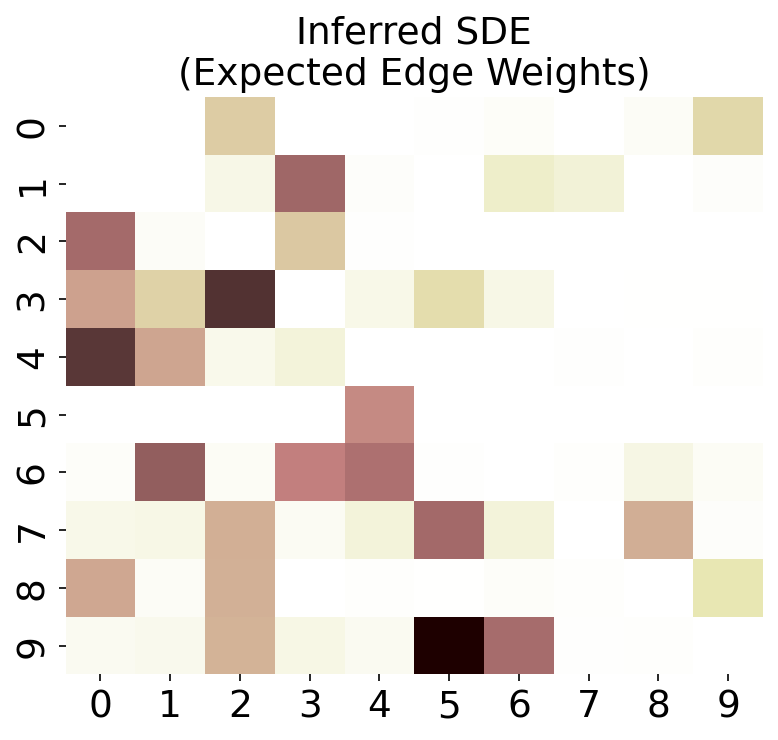

In [82]:
print("--- Graph-Tool SDE Results ---")
print(f"AUPRC:     {results['Graph-Tool SDE (EM)']['AUPRC']:.4f}")
print(f"AUROC:     {results['Graph-Tool SDE (EM)']['AUROC']:.4f}")
print(f"Spearman:  {results['Graph-Tool SDE (EM)']['Spearman']:.4f}")
print(f"Sign Acc:  {results['Graph-Tool SDE (EM)']['Sign Accuracy']:.4f}")
print(f"Train MSE: {results['Graph-Tool SDE (EM)']['Train MSE']:.4f}")
print(f"Test MSE:  {results['Graph-Tool SDE (EM)']['Test MSE']:.4f}")

plt.figure(figsize=(6, 5))
W_gt_plot = gt_edge_scores.copy()
np.fill_diagonal(W_gt_plot, 0)
sns.heatmap(W_gt_plot, cmap='pink_r', cbar=False)
plt.title('Inferred SDE\n(Expected Edge Weights)')
plt.show()


## Final Comparison Plots


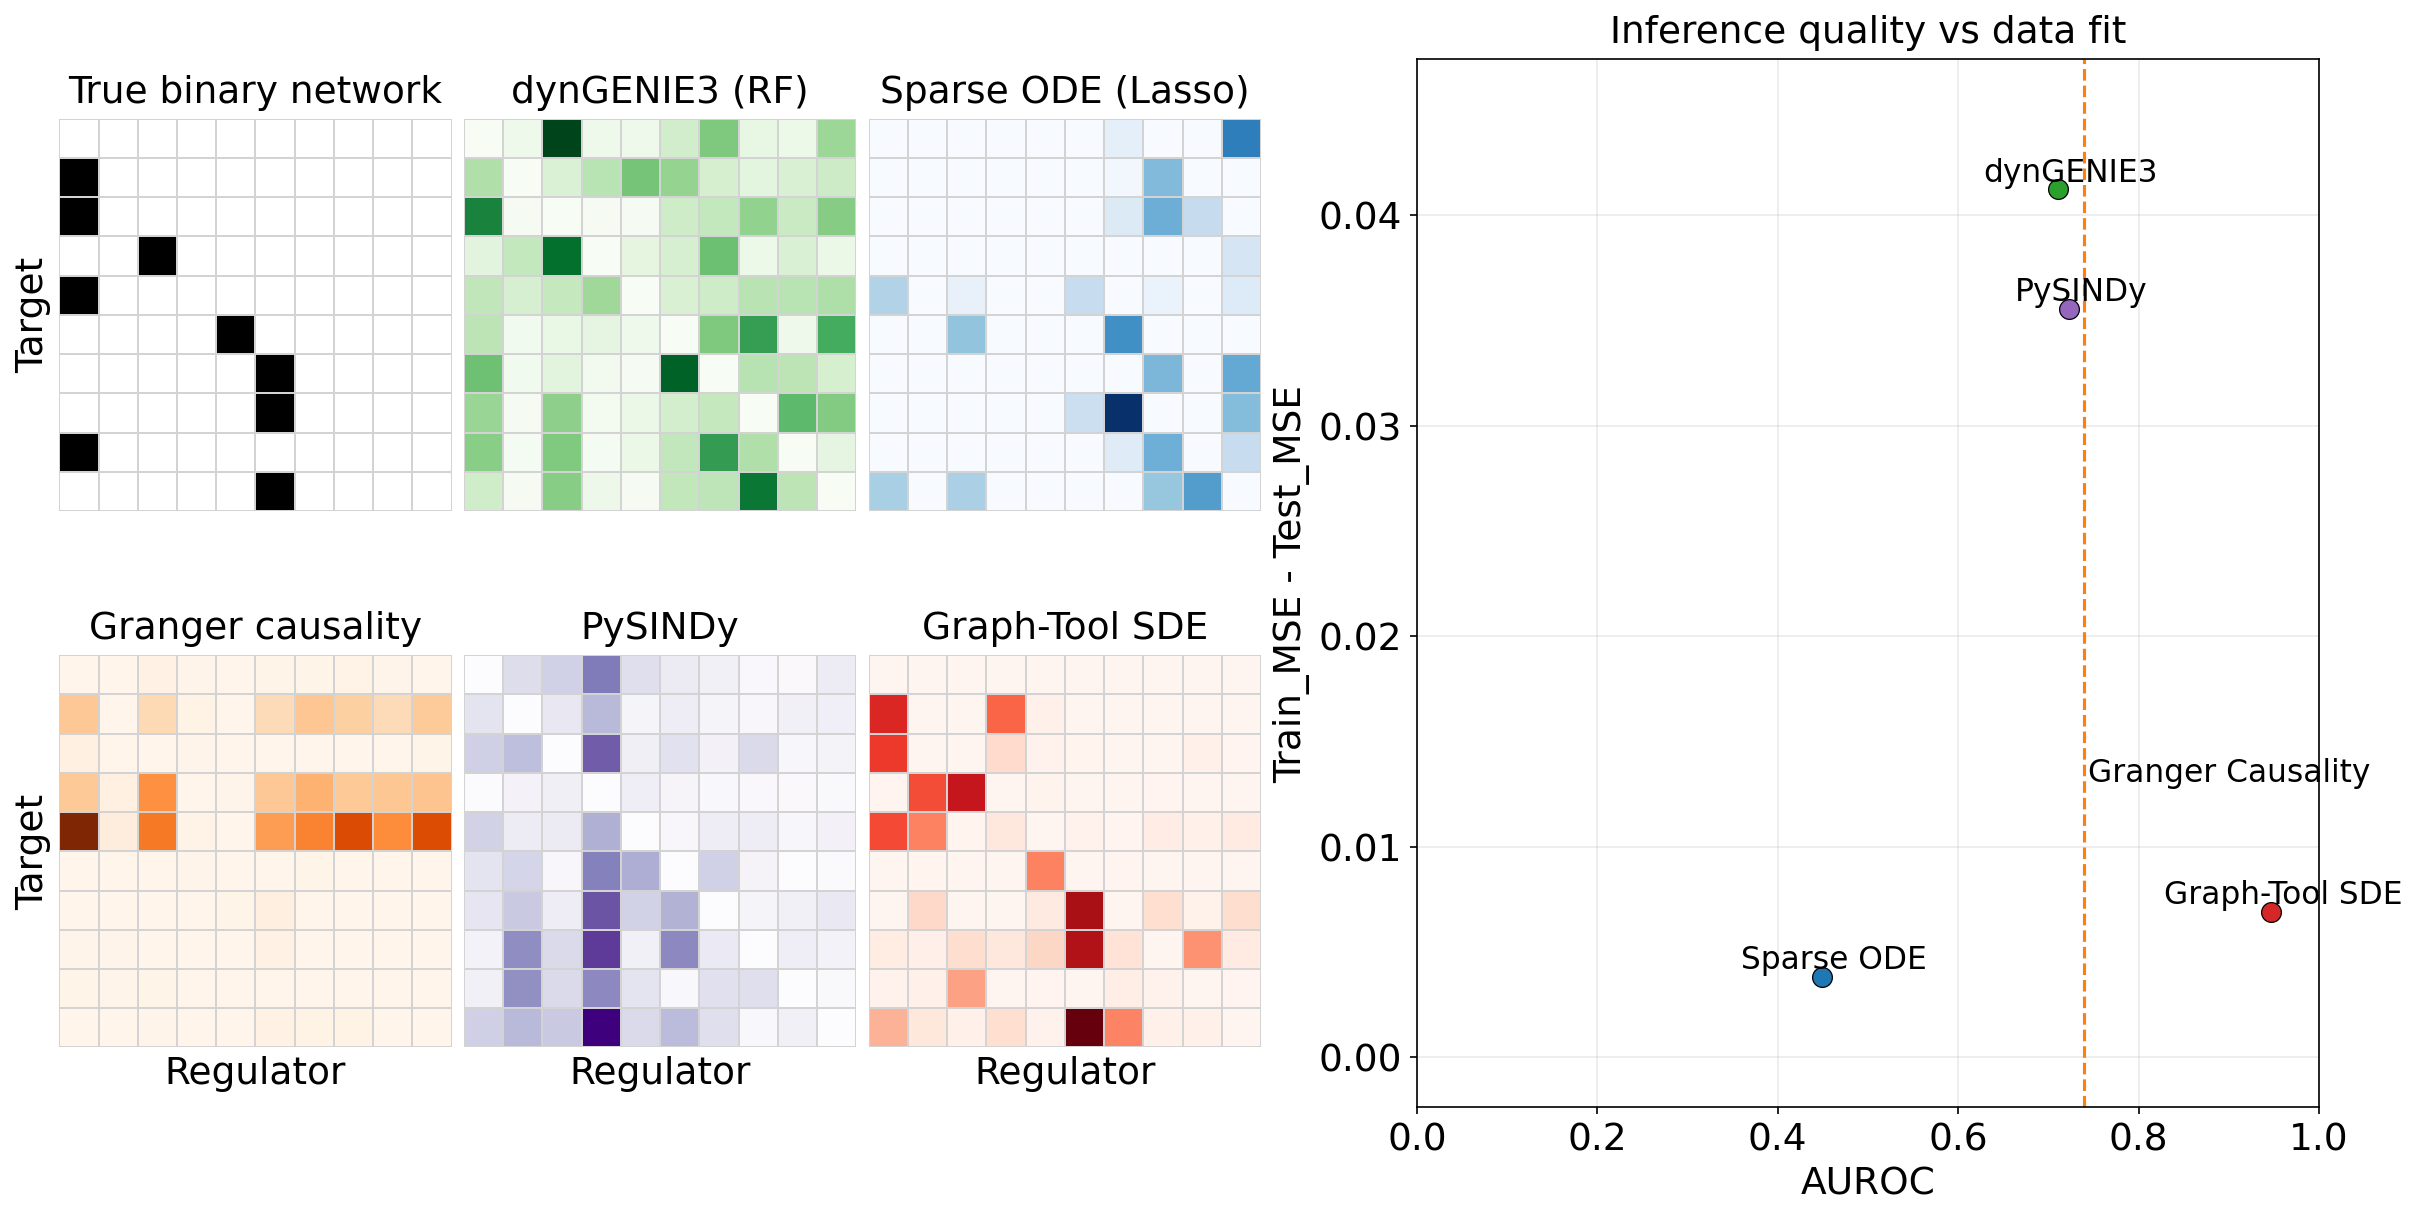

In [86]:
import matplotlib.gridspec as gridspec

results["Graph-Tool SDE"] = dict(np.load("data/Graph-Tool_SDE_results.npz", allow_pickle=True))

plt.rcParams.update({
    "font.size": 18,
    "axes.titlesize": 18,
    "axes.labelsize": 18,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "legend.fontsize": 18,
    "figure.dpi": 150,
    "savefig.dpi": 300,
})

methods = [
    "dynGENIE3 (RF)",
    "Sparse ODE (Lasso)",
    "Granger Causality",
    "PySINDy",
    "Graph-Tool SDE",
    #"Graph-Tool SDE (EM)"
]

color_map = {
    'dynGENIE3 (RF)': 'tab:green',
    'Sparse ODE (Lasso)': 'tab:blue',
    'Granger Causality': 'tab:orange',
    'PySINDy': 'tab:purple',
    'Graph-Tool SDE': 'tab:red',
    #'Graph-Tool SDE (EM)': 'tab:pink'
}

fig = plt.figure(figsize=(16, 8), constrained_layout=True)
gs = gridspec.GridSpec(2, 4, figure=fig, width_ratios=[1, 1, 1, 2.3])

axes = {
    "true": fig.add_subplot(gs[0, 0]),
    "rf": fig.add_subplot(gs[0, 1]),
    "lasso": fig.add_subplot(gs[0, 2]),
    "gc": fig.add_subplot(gs[1, 0]),
    "sindy": fig.add_subplot(gs[1, 1]),
    "gt": fig.add_subplot(gs[1, 2]),
    "scatter": fig.add_subplot(gs[:, 3]),
}

def plot_heat(ax, mat, title, cmap):
    m = mat.copy()
    np.fill_diagonal(m, 0)
    sns.heatmap(
        m,
        ax=ax,
        cmap=cmap,
        square=True,
        cbar=False,
        xticklabels=False,
        yticklabels=False,
        linewidths=0.2,
        linecolor="lightgray",
    )
    ax.set_title(title, pad=8)

plot_heat(axes["true"], W_true_binary, "True binary network", "Greys")
plot_heat(axes["rf"], results["dynGENIE3 (RF)"]["W"], "dynGENIE3 (RF)", "Greens")
plot_heat(axes["lasso"], results["Sparse ODE (Lasso)"]["W"], "Sparse ODE (Lasso)", "Blues")
plot_heat(axes["gc"], results["Granger Causality"]["W"], "Granger causality", "Oranges")
plot_heat(axes["sindy"], results["PySINDy"]["W"], "PySINDy", "Purples")
plot_heat(axes["gt"], results["Graph-Tool SDE"]["W"], "Graph-Tool SDE", "Reds")

axes["true"].set_ylabel("Target")
axes["gc"].set_ylabel("Target")
axes["gc"].set_xlabel("Regulator")
axes["sindy"].set_xlabel("Regulator")
axes["gt"].set_xlabel("Regulator")

# Scatter: predictive fit vs inference quality
x_metric = "AUROC"
y_metric = "Train_MSE - Test_MSE"

y_values = []
for method in methods:
    res = results[method]
    x_val = res.get(x_metric, np.nan)
    train_val = res.get("Train_MSE", np.nan)
    test_val = res.get("Test_MSE", np.nan)

    if np.isnan(x_val) or np.isnan(train_val) or np.isnan(test_val):
        continue

    y_values.append(np.abs(train_val - test_val))

for method in methods:
    res = results[method]
    x_val = res.get(x_metric, np.nan)
    train_val = res.get("Train_MSE", np.nan)
    test_val = res.get("Test_MSE", np.nan)

    if np.isnan(x_val) or np.isnan(train_val) or np.isnan(test_val):
        continue

    y_val = np.abs(train_val - test_val)
    axes["scatter"].scatter(
        x_val,
        y_val,
        s=90,
        color=color_map[method],
        edgecolor="black",
        linewidth=0.6,
        label=method,
        zorder=3,
    )
    axes["scatter"].annotate(
        method.replace(" (RF)", "").replace(" (Lasso)", ""),
        (x_val, y_val),
        textcoords="offset points",
        xytext=(6, 4),
        ha="center",
        fontsize=15,
    )

axes["scatter"].set_xlim([0.0, 1.0])
axes["scatter"].set_xlabel(x_metric)

if y_values:
    ymin = np.nanmin(y_values)
    ymax = np.nanmax(y_values)
    pad = 0.15 * max(abs(ymin), abs(ymax), 1e-8)
    axes["scatter"].set_ylim([ymin - pad, ymax + pad])
else:
    axes["scatter"].set_ylim([0, 1])

axes["scatter"].set_ylabel(y_metric)
axes["scatter"].set_title("Inference quality vs data fit", pad=8)
axes["scatter"].grid(True, alpha=0.25, zorder=0)

axes["scatter"].axvline(
    x=results["Granger Causality"][x_metric],
    color="tab:orange",
    linestyle="--",
    linewidth=1.5,
    label="Granger Causality",
)
axes["scatter"].text(
    results["Granger Causality"][x_metric] + 0.005,
    axes["scatter"].get_ylim()[1] * 0.3,
    "Granger Causality",
    color="k",
    fontsize=15,
    va="top",
)

plt.savefig("../images/inference_quality_vs_fit.png", dpi=300, bbox_inches="tight")